# Task 1: Data Cleaning & Preprocessing

## 1. Importing and Exploring the Dataset

### Purpose

Load the Titanic passenger data and understand its structure before making changes. These first checks are exploratory: they describe the data but do not clean or modify it.

### What the checks show

- `df.shape` reports the number of rows and columns.
- `df.head()` previews the first records so we can see how values are stored.
- `df.columns` lists the available feature names.
- `df.info()` shows each column's data type and non-missing value count.
- `df.describe()` summarizes numerical columns; `df.describe(include="all")` also includes categorical columns.
- `df.isnull().sum()` counts missing values in each column.
- `df.duplicated().sum()` checks whether any complete rows are repeated.

### Why this matters

Exploration helps identify data quality issues and understand which cleaning steps are needed before analysis or modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Titanic-Dataset.csv")
df.shape

(891, 12)

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
## Statistical Summary
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
##DEscription all features
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
if df.duplicated().sum():
    print(f"Number of duplicates in the dataset are {df.duplicated().sum()}")
else:
    print("There is No duplicates")


There is No duplicates


## 2. Handling Missing Values

### Purpose

Find missing entries and choose a replacement or representation that suits each column. The percentage calculation shows how much of each column is missing, and the previews help inspect the affected values.

### What this notebook does

- Fills missing `Age` values with the median age. The median is less affected by unusually high or low ages than the mean.
- Fills missing `Embarked` values with the most frequent port, or mode, because `Embarked` is categorical.
- Handles `Cabin` separately because most entries are missing and the raw cabin labels have many distinct values. The next note explains how the notebook keeps a simpler deck feature instead.

### Why this matters

Missing values can prevent analysis or modeling methods from working. The replacement should match the type and meaning of the feature; one method is not automatically suitable for every column.

In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage[missing_percentage > 0].sort_values(ascending=False)

Cabin       77.104377
Age         19.865320
Embarked     0.224467
dtype: float64

In [11]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
df[["Age", "Embarked"]].head(10)

,Age,Embarked
0,22.0,S
1,38.0,C
2,26.0,S
3,35.0,S
4,35.0,S
5,NaN,Q
6,54.0,S
7,2.0,S
8,27.0,S
9,14.0,C


In [13]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [14]:
# Fill missing Age values with the median
df["Age"] = df["Age"].fillna(df["Age"].median())


# Fill missing Embarked values with the mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])


In [15]:
df.Cabin.head(10)

0     NaN
1     C85
2     NaN
3    C123
4     NaN
5     NaN
6     E46
7     NaN
8     NaN
9     NaN
Name: Cabin, dtype: str

In [16]:
df['Cabin'].isnull().sum()

np.int64(687)

### Why transform `Cabin`?

About 77% of `Cabin` entries are missing, and the full cabin labels contain many distinct values. The notebook extracts the first character as a simpler `Deck` category and assigns missing cabins to `Unknown`. It then drops the original `Cabin` column to avoid keeping both the detailed identifier and its derived feature.

This preserves a broad deck signal while avoiding a separate category for every cabin number. `Unknown` means the deck could not be determined from the available data; it is not a known deck.

In [17]:
# Extract the first character of the Cabin value to represent the deck.
# Missing Cabin values are assigned to "Unknown".

df["Deck"] = df["Cabin"].str[0].fillna("Unknown")
df[["Cabin", "Deck"]].head(10)

,Cabin,Deck
0,NaN,Unknown
1,C85,C
2,NaN,Unknown
3,C123,C
4,NaN,Unknown
5,NaN,Unknown
6,E46,E
7,NaN,Unknown
8,NaN,Unknown
9,NaN,Unknown


In [18]:
df["Deck"].value_counts(dropna=False)

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [19]:
df.drop("Cabin", axis=1, inplace=True)

In [20]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Deck           0
dtype: int64

In [21]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown


### 5. Outlier Detection and Removal

#### What is an outlier?

A boxplot summarizes a feature's distribution. The box spans the first quartile (Q1) to the third quartile (Q3), the line inside is the median, and the whiskers extend to the most extreme values within 1.5 times the interquartile range (IQR). Points beyond the whiskers are potential outliers, not necessarily mistakes.

#### How will we identify them?


We inspect all four numerical features: `Age`, `SibSp`, `Parch`, and `Fare`. For each feature, calculate `IQR = Q3 - Q1`; values below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR` are flagged. The orange dashed lines show these original fences, and the tables report flags for every feature.

The features are not all the same kind of data. `Age` and `Fare` are continuous measurements, while `SibSp` and `Parch` are discrete family counts. In this dataset, `Parch` has Q1 = Q3 = 0, so the IQR rule flags every passenger with a nonzero `Parch` count. Those values can be perfectly valid, so the count columns are inspected and reported but do not cause rows to be removed.

This section runs before feature scaling, so plots and fences use the original units and do not need a scaler.

#### How will we remove them?

For this exercise, remove a passenger row if either `Age` or `Fare` is outside its IQR fences. The before-and-after plots show which features drive removal; `SibSp` and `Parch` are left unchanged. Some flagged ages or fares may still be genuine, so this rule is a simplifying preprocessing choice rather than proof that those records are wrong.

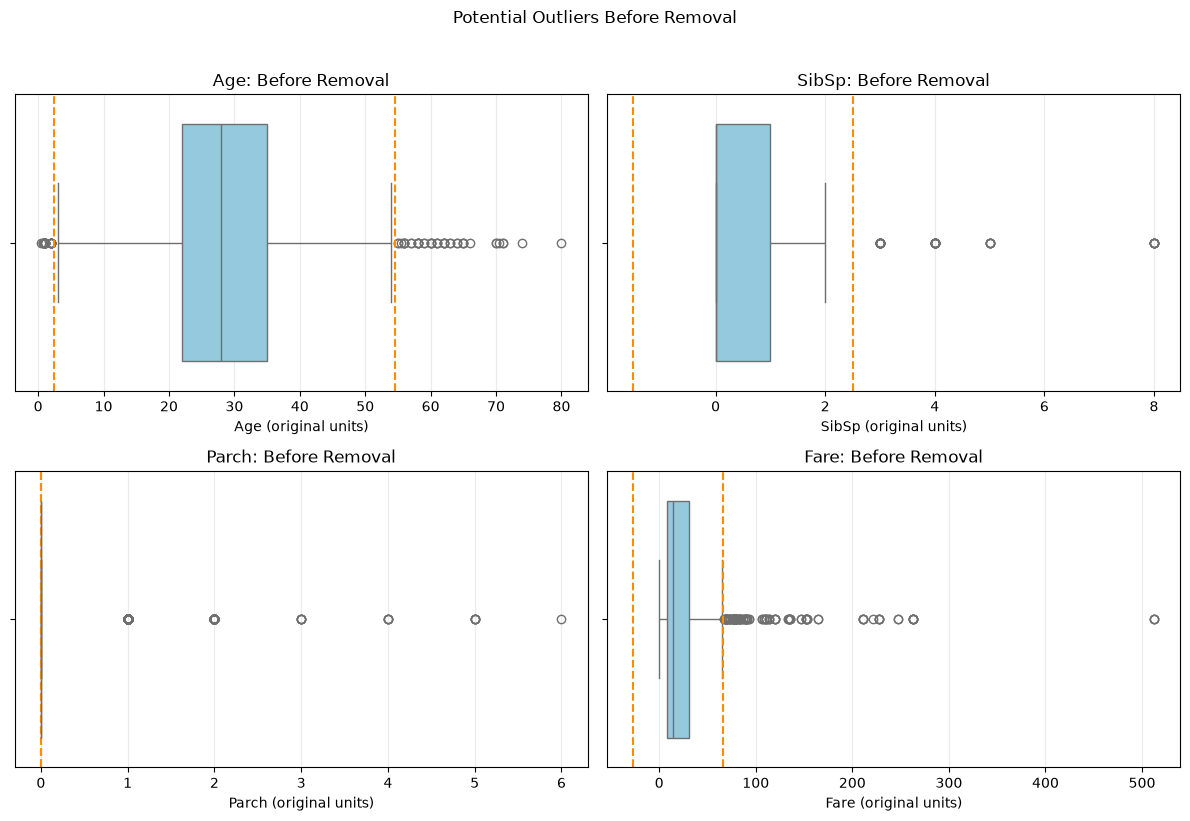

In [22]:
# Inspect all four numerical features in their original units.
outlier_features = ["Age", "SibSp", "Parch", "Fare"]
removal_features = ["Age", "Fare"]
outlier_data = df[outlier_features].copy()

# Calculate the IQR fences before plotting so they can be shown on the charts.
Q1 = outlier_data.quantile(0.25)
Q3 = outlier_data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(outlier_features, axes.flat):
    sns.boxplot(x=outlier_data[col], ax=ax, color="skyblue")
    ax.axvline(lower_bound[col], color="darkorange", linestyle="--")
    ax.axvline(upper_bound[col], color="darkorange", linestyle="--")
    ax.set_title(f"{col}: Before Removal")
    ax.set_xlabel(f"{col} (original units)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Potential Outliers Before Removal", y=1.02)
fig.tight_layout()
plt.show()

In [23]:
# Review the quartiles and IQR fences used to flag potential outliers.
iqr_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower fence": lower_bound,
    "Upper fence": upper_bound
})
iqr_summary

,Q1,Q3,IQR,Lower fence,Upper fence
Age,22.0000,35.0,13.0000,2.500,54.5000
SibSp,0.0000,1.0,1.0000,-1.500,2.5000
Parch,0.0000,0.0,0.0000,0.000,0.0000
Fare,7.9104,31.0,23.0896,-26.724,65.6344


In [24]:
# True means that this feature value is outside its IQR fences.
outlier_mask = (
    (outlier_data.lt(lower_bound)) |
    (outlier_data.gt(upper_bound))
)

# These per-feature counts may overlap when a passenger is flagged more than once.
outlier_counts = outlier_mask.sum().rename("Flagged values")
outlier_summary = pd.concat(
    [
        outlier_counts,
        (outlier_counts / len(outlier_data) * 100).rename("Percent of passengers")
    ],
    axis=1
)
print(f"Passengers flagged in at least one of the four features: {outlier_mask.any(axis=1).sum()}")
outlier_summary

Passengers flagged in at least one of the four features: 314


,Flagged values,Percent of passengers
Age,66,7.407407
SibSp,46,5.162738
Parch,213,23.905724
Fare,116,13.019080


In [25]:
print(f"Dataset shape before removal: {df.shape}")

Dataset shape before removal: (891, 12)


In [26]:
rows_before_removal = len(df)
rows_to_remove = outlier_mask[removal_features].any(axis=1)
count_flags_retained = (
    outlier_mask[["SibSp", "Parch"]].any(axis=1) & ~rows_to_remove
).sum()
df = df.loc[~rows_to_remove].copy()
rows_removed = rows_before_removal - len(df)

print(f"Rows removed based on Age/Fare: {rows_removed}")
print(f"Rows remaining: {len(df)} of {rows_before_removal}")
print(f"Percentage retained: {len(df) / rows_before_removal:.1%}")
print(f"Rows flagged only by family counts and retained: {count_flags_retained}")
df.shape

Rows removed based on Age/Fare: 170
Rows remaining: 721 of 891
Percentage retained: 80.9%
Rows flagged only by family counts and retained: 144


(721, 12)

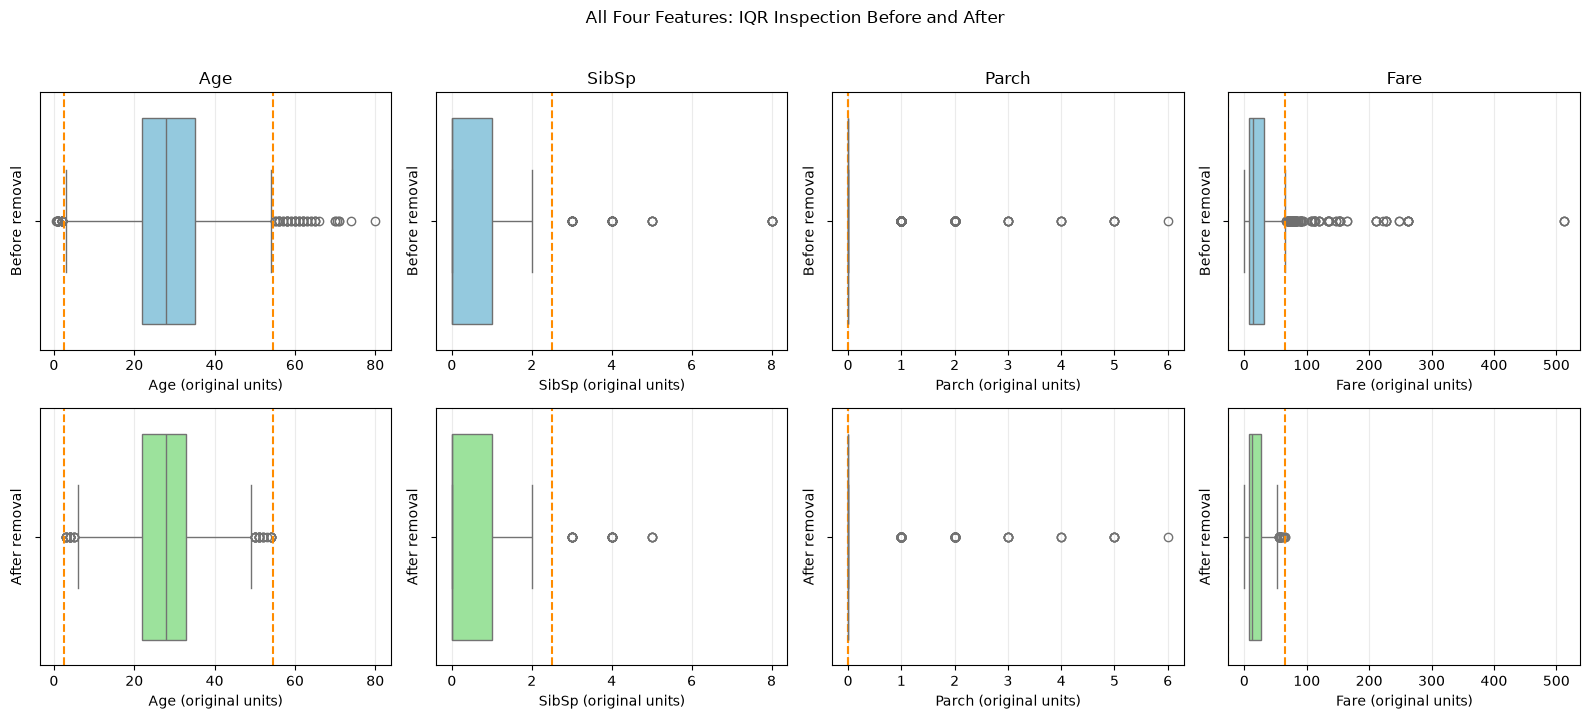

In [27]:
# Compare all four features before and after the Age/Fare removal rule.
fig, axes = plt.subplots(2, len(outlier_features), figsize=(16, 7))
for col_index, col in enumerate(outlier_features):
    value_min = outlier_data[col].min()
    value_max = outlier_data[col].max()
    padding = (value_max - value_min) * 0.05

    for row_index, values in enumerate((outlier_data[col], df[col])):
        ax = axes[row_index, col_index]
        sns.boxplot(
            x=values,
            ax=ax,
            color="skyblue" if row_index == 0 else "lightgreen"
        )
        ax.axvline(lower_bound[col], color="darkorange", linestyle="--")
        ax.axvline(upper_bound[col], color="darkorange", linestyle="--")
        ax.set_xlim(value_min - padding, value_max + padding)
        ax.set_xlabel(f"{col} (original units)")
        ax.set_ylabel("Before removal" if row_index == 0 else "After removal")
        ax.grid(axis="x", alpha=0.25)
        if row_index == 0:
            ax.set_title(col)

fig.suptitle("All Four Features: IQR Inspection Before and After", y=1.02)
fig.tight_layout()
plt.show()

## 3. Categorical Encoding

### Purpose

Convert selected categorical features into numeric representations while preserving their meaning. Different encodings are used depending on whether a feature has two categories or several nominal categories.

### What this notebook does

- Maps `Sex` to 0 for male and 1 for female. These numbers are category labels, not a ranking.
- One-hot encodes `Embarked` and the derived `Deck` feature. Each category gets its own indicator column, so the encoding does not imply an order.
- Leaves `Name` and `Ticket` unencoded because they contain many distinct values. They remain text columns in `df`; a numeric-only model would need these columns removed or converted into useful features first.

The target `Survived` is not part of these input-feature encodings.

In [28]:
categorical_columns = df.select_dtypes(include=['object', 'str']).columns
categorical_columns

Index(['Name', 'Sex', 'Ticket', 'Embarked', 'Deck'], dtype='str')

In [29]:
for col in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"{col}")
    print(f"{'=' * 50}")
    print(df[col].value_counts())


Name
Name
Braund, Mr. Owen Harris                         1
Heikkinen, Miss. Laina                          1
Futrelle, Mrs. Jacques Heath (Lily May Peel)    1
Allen, Mr. William Henry                        1
Moran, Mr. James                                1
                                               ..
Montvila, Rev. Juozas                           1
Graham, Miss. Margaret Edith                    1
Johnston, Miss. Catherine Helen "Carrie"        1
Behr, Mr. Karl Howell                           1
Dooley, Mr. Patrick                             1
Name: count, Length: 721, dtype: int64

Sex
Sex
male      490
female    231
Name: count, dtype: int64

Ticket
Ticket
1601               7
347082             6
CA 2144            5
347088             5
347077             4
                  ..
SOTON/OQ 392076    1
211536             1
112053             1
111369             1
370376             1
Name: count, Length: 600, dtype: int64

Embarked
Embarked
S    545
C    105
Q     71
Name: 

### Encoding decisions

- `Sex` has two categories, so the code maps it to 0 and 1.
- `Embarked` and `Deck` are nominal categories with no natural order, so the code creates one-hot indicator columns for them.
- `Name` and `Ticket` are not encoded because they have many distinct values. They stay in the dataframe as text and would need separate handling before use with a model that accepts only numeric inputs.
- `handle_unknown="ignore"` lets the encoder handle a category it did not see during fitting without raising an error.

In [30]:
# Binary/label encoding is suitable because Sex has only two categories
# and there is no need to create multiple columns.
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

In [31]:
from sklearn.preprocessing import OneHotEncoder

# One-hot encoding is suitable because these are nominal categories
# with no meaningful order.
encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)
encoded_data = encoder.fit_transform(df[["Embarked", "Deck"]])

In [32]:
encoded_columns = encoder.get_feature_names_out(["Embarked", "Deck"])
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=df.index
)

In [33]:
df = pd.concat(
    [df.drop(["Embarked", "Deck"], axis=1), encoded_df],
    axis=1
)

In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 721 entries, 0 to 890
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   721 non-null    int64  
 1   Survived      721 non-null    int64  
 2   Pclass        721 non-null    int64  
 3   Name          721 non-null    str    
 4   Sex           721 non-null    int64  
 5   Age           721 non-null    float64
 6   SibSp         721 non-null    int64  
 7   Parch         721 non-null    int64  
 8   Ticket        721 non-null    str    
 9   Fare          721 non-null    float64
 10  Embarked_C    721 non-null    float64
 11  Embarked_Q    721 non-null    float64
 12  Embarked_S    721 non-null    float64
 13  Deck_A        721 non-null    float64
 14  Deck_B        721 non-null    float64
 15  Deck_C        721 non-null    float64
 16  Deck_D        721 non-null    float64
 17  Deck_E        721 non-null    float64
 18  Deck_F        721 non-null    float64
 19  Dec

In [35]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,6,0,3,"Moran, Mr. James",0,28.0,0,0,330877,8.4583,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 4. Feature Scaling

### Purpose

Put selected numeric columns on a comparable scale. `StandardScaler` subtracts each column's mean and divides by its standard deviation, producing values centered around 0 with a standard deviation around 1.

### What this notebook does

The code applies standardization to `PassengerId`, `Pclass`, `Age`, `SibSp`, `Parch`, and `Fare`. It leaves `Survived` unchanged because that is the target column, not an input feature. Scaling changes the units of these columns; it does not remove outliers or make their distributions normal.

### Modeling note

The current code fits the scaler on the full dataframe. For a model evaluation, split the data first, fit the scaler on the training data only, and use that fitted scaler to transform validation or test data. `PassengerId` is an identifier and `Pclass` is an ordered category, so whether they should be scaled depends on the model and feature design.

In [ ]:
# Numerical input features to be standardized.
# Survived is excluded because it is the target variable.
numerical_features = [

    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

In [37]:
from sklearn.preprocessing import StandardScaler

# Standardization is appropriate because these numerical features
# have different ranges and units.
scaler = StandardScaler()

df[numerical_features] = scaler.fit_transform(df[numerical_features])

In [38]:
df[numerical_features].describe().loc[["mean", "std", "min", "max"]]

,Pclass,Age,SibSp,Parch,Fare
mean,-2.710114e-16,-1.872443e-16,-9.854962e-18,-6.282538e-17,5.420229e-17
std,1.000694e+00,1.000694e+00,1.000694e+00,1.000694e+00,1.000694e+00
min,-2.105950e+00,-2.505671e+00,-4.859842e-01,-4.101032e-01,-1.283040e+00
max,6.852081e-01,2.586686e+00,5.373458e+00,7.204088e+00,3.512724e+00


In [39]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
0,1,0,0.685208,"Braund, Mr. Owen Harris",0,-0.608518,0.685904,-0.410103,A/5 21171,-0.748128,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,3,1,0.685208,"Heikkinen, Miss. Laina",1,-0.209117,-0.485984,-0.410103,STON/O2. 3101282,-0.698326,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,4,1,-2.105950,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0.689534,0.685904,-0.410103,113803,2.634730,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,0,0.685208,"Allen, Mr. William Henry",0,0.689534,-0.485984,-0.410103,373450,-0.689103,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,6,0,0.685208,"Moran, Mr. James",0,-0.009417,-0.485984,-0.410103,330877,-0.658978,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
